In [356]:
import numpy as np
from dynamics import Dynamics
import matplotlib.pyplot as plt

In [357]:
class PendulumDynamics():
    def __init__(self):
        self.dt = 0.02
        self.u_max = 1
        self.n = 2
        self.m = 1
        self.g = 9.81
        self.l = 1.0

    def step(self, x_batch: np.ndarray, u_batch: np.ndarray) -> np.ndarray:  # 수정: ndarry 오타
        """
        evaluate pendulum dynamics.

        Args:
            x: state vector, [θ, dθ_dt]
            t: time [s]
            g: acceleration due to gravity [m/s^2]
            l: pendulum length [m]
        """
        u_clip = np.clip(u_batch, -self.u_max, self.u_max)
        dx = np.array([x_batch[1, :], -self.g/self.l*np.sin(x_batch[0, :]) + u_clip])
        dth = x_batch[1] + dx[1] * self.dt
        th = x_batch[0] + dth * self.dt
        x_next = np.array([th, dth])
        #x_next = x_batch + dx * self.dt
        return x_next

    def rollout(self, x0: np.ndarray, u_sequence: np.ndarray) -> np.ndarray:
        T = u_sequence.shape[1]
        num_rollouts = u_sequence.shape[0]

        rollouts = np.zeros((self.n, T + 1, num_rollouts))
        rollouts[:, 0, :] = np.tile(x0[:, None], (1, num_rollouts))
        for t in range(T):
            rollouts[:, t+1, :] = self.step(rollouts[:, t, :], u_sequence[:, t])

        return rollouts

In [386]:
class MPPIController():
    def __init__(self):
        self.K = 100
        self.lamda = 1.0
        self.T = 50
        self.rng = np.random.default_rng(0)
        self.dynamics = PendulumDynamics()
        self.H = 1500

    def sampling(self, u_prev) -> np.ndarray:  # 수정: self 추가
        sigma = 1.0
        u_batch = self.rng.normal(u_prev, sigma, size=(self.K, self.T))
        u_clip = np.clip(u_batch, -self.dynamics.u_max, self.dynamics.u_max)
        return u_clip

    def cost_function(self, x: np.ndarray) -> np.ndarray:
        J = 0
        for t in range(self.T + 1):  # 수정: T → self.T
            J += 500 * (np.cos(x[0,t]) + 1)**2 + 15 * x[1,t]**2
        return J

    def cost_evaluation(self, x0, u_batch) -> np.ndarray:  # 수정: 인자 받기
        J_batch = np.zeros((self.K))  # 수정: K → self.K
        rollouts = self.dynamics.rollout(x0, u_batch)  # 수정: 인자 채우기
        for k in range(self.K):
            J_batch[k] = self.cost_function(rollouts[:,:,k])
        return J_batch

    def get_weight(self, J_batch):
        J_min = np.min(J_batch)
        weight = np.exp(-1/self.lamda * (J_batch - J_min))
        softmax = weight/np.sum(weight)
        return softmax

    def get_rollout(self, x0, u):
        u_history = []
        x_history = [x0]
        for _ in range(self.H):    
            u_new = self.forward(x0, u)
            x_new = self.dynamics.step(x0[:,None], u_new[0])
            x0 = x_new[:, 0]
            u_history.append(u_new[0])
            x_history.append(x0)
            for t in range(self.T-1):
                u_new[t] = u_new[t+1]
            u = np.copy(u_new)
        return x_history, u_history

    def forward(self, x0, u_prev):
        #1. x0 입력 받아
        #2-1. K개의 u_sequence를 sampling하여
        u_batch = self.sampling(u_prev)
        #2-2. K개의 rollout을 얻어낸 후
        #2-3. K개의 rollout에 대한 cost evaluation을 진행
        J_batch = self.cost_evaluation(x0, u_batch)
        #3. Softmax 가중치 계산
        w = self.get_weight(J_batch)
        #4. 최적의 u_mean 업데이트
        u_new = w @ u_batch
        #5. u_mean return (첫번째 u만 execute)
        return u_new

    def Energy(self, x):
        g = self.dynamics.g
        l = self.dynamics.l
        return 1/2 * x[1] **2 + g/l*(1-np.cos(x[0]))


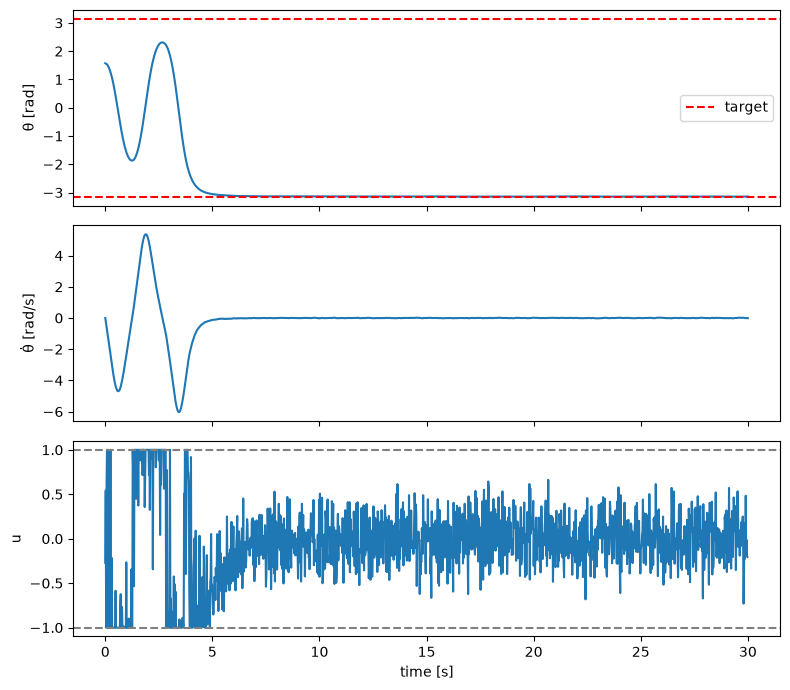

In [392]:
#Swing-Up at pi/2

controller = MPPIController()
u_initial = np.zeros((controller.T))
x0 = np.array([np.pi/2, 0])
x_history, u_history = controller.get_rollout(x0, u_initial)

X = np.array(x_history)
U = np.array(u_history)
dt = controller.dynamics.dt
t_x = np.arange(len(X)) * dt
t_u = np.arange(len(U)) * dt

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 7))

axes[0].plot(t_x, X[:, 0])
axes[0].axhline(np.pi, ls="--", c="r", label="target")
axes[0].axhline(-np.pi, ls="--", c="r")
axes[0].set_ylabel("θ [rad]")
axes[0].legend()

axes[1].plot(t_x, X[:, 1])
axes[1].set_ylabel("θ̇ [rad/s]")

axes[2].plot(t_u, U)
axes[2].axhline(controller.dynamics.u_max, ls="--", c="gray")
axes[2].axhline(-controller.dynamics.u_max, ls="--", c="gray")
axes[2].set_ylabel("u")
axes[2].set_xlabel("time [s]")

plt.tight_layout()
plt.show()

최종 상대 변화: 0.017751159679550033
최대 상대 오차: 0.03015292882032491


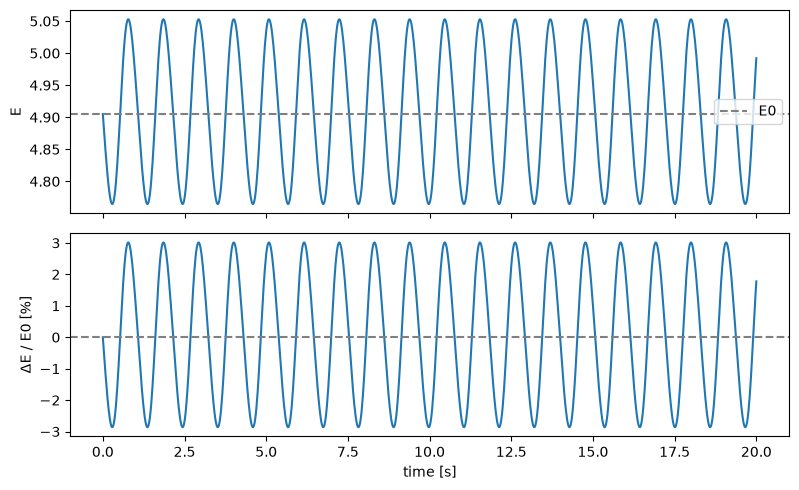

In [360]:
#Energy Test
x0 = np.array([np.pi/3, 0])
u = np.array([0])
E_history = [controller.Energy(x0)]
for _ in range(1000):
    x_new = controller.dynamics.step(x0[:,None],u)
    x0 = np.copy(x_new[:,0])
    E_history.append(controller.Energy(x0))

E = np.array(E_history).squeeze()
dt = controller.dynamics.dt
t = np.arange(len(E)) * dt
rel = (E - E[0]) / E[0]

print("최종 상대 변화:", rel[-1])
print("최대 상대 오차:", np.abs(rel).max())

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))

axes[0].plot(t, E)
axes[0].axhline(E[0], ls="--", c="gray", label="E0")
axes[0].set_ylabel("E")
axes[0].legend()

axes[1].plot(t, rel * 100)
axes[1].axhline(0, ls="--", c="gray")
axes[1].set_ylabel("ΔE / E0 [%]")
axes[1].set_xlabel("time [s]")

plt.tight_layout()
plt.show()

In [387]:
rng = np.random.default_rng(1)
th0 = rng.uniform(-np.pi, np.pi, size=10)
err_list = []
for j in range(len(th0)):
    u_initial = np.zeros((controller.T))
    x0 = np.array([th0[j], 0])
    controller = MPPIController()
    x_history, u_history = controller.get_rollout(x0, u_initial)
    last_5s_step = int(5 / controller.dynamics.dt)
    θ_5s_list = np.array(x_history[-last_5s_step][0])
    err = np.abs(θ_5s_list % (2*np.pi) - np.pi)
    err_max = err.max()
    err_list.append(err_max)
    print(f"{j+1}번째 초기값 완료")
        

1번째 초기값 완료
2번째 초기값 완료
3번째 초기값 완료
4번째 초기값 완료
5번째 초기값 완료
6번째 초기값 완료
7번째 초기값 완료
8번째 초기값 완료
9번째 초기값 완료
10번째 초기값 완료


In [398]:
np.rad2deg(max(err_list))

[ 0.07427746  2.83034688 -2.23581109  2.81894761 -1.18229786 -0.48175413
  2.05901612 -0.57051865  0.31160633 -2.96843364]


np.float64(180.0)

In [ ]:
!git config user.name "dnltjrqja-dev" && git config user.email "내이메일"
